In [55]:
import os
import mlflow
import numpy as np
import pandas as pd
import mlflow.keras
import tensorflow as tf
from datetime import datetime
import matplotlib.pyplot as plt
from typing import List, Optional
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error
from dateutil.relativedelta import relativedelta
from mlflow.models.signature import infer_signature
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from tensorflow.keras.models import Model, Sequential, load_model
from tensorflow.keras.layers import Input, GRU, LSTM, Conv1D, Dense, Dropout, Embedding, Concatenate, Flatten

In [56]:
dp = f"./data/thesis-data.csv"

# Load or Download Data
if os.path.exists(dp):
    data = pd.read_csv(dp)

# Preprocess Data
if 'date' not in data.columns:
    data.reset_index(inplace=True)  # Reset index to bring 'date' as a column
# Convert column names to lowercase
data.columns = data.columns.str.lower()
# Ensure 'date' is the index
data["date"] = pd.to_datetime(data["date"])  # Convert to datetime format
data.set_index("date", inplace=True)
# data = data.drop("unnamed: 0", axis=1)

In [61]:
data

,open,high,low,close,volume,ticker,interval,gaussian_channel_middle,gaussian_channel_upper,gaussian_channel_lower,...,fibonacci_retracement_61.8,fibonacci_retracement_100.0,price_action_open,price_action_high,price_action_low,price_action_close,momentum,williams_r,chaikin_money_flow,obv
date,,,,,,,,,,,,,,,,,,,,,
1965-01-05,1257.719971,1257.719971,1257.719971,1257.719971,0,N225,1d,1263.018500,1294.482547,1231.554453,...,38483.482102,37742.761719,1257.719971,1257.719971,1257.719971,1257.719971,0.489990,-100.000000,0.0,0
1965-01-06,1263.989990,1263.989990,1263.989990,1263.989990,0,N225,1d,1263.018500,1294.482547,1231.554453,...,38483.482102,37742.761719,1263.989990,1263.989990,1263.989990,1263.989990,0.489990,-100.000000,0.0,0
1965-01-07,1274.270020,1274.270020,1274.270020,1274.270020,0,N225,1d,1263.018500,1294.482547,1231.554453,...,38483.482102,37742.761719,1274.270020,1274.270020,1274.270020,1274.270020,0.489990,-100.000000,0.0,0
1965-01-08,1286.430054,1286.430054,1286.430054,1286.430054,0,N225,1d,1263.018500,1294.482547,1231.554453,...,38483.482102,37742.761719,1286.430054,1286.430054,1286.430054,1286.430054,0.489990,-100.000000,0.0,0
1965-01-12,1288.540039,1288.540039,1288.540039,1288.540039,0,N225,1d,1263.018500,1294.482547,1231.554453,...,38483.482102,37742.761719,1288.540039,1288.540039,1288.540039,1288.540039,0.489990,-100.000000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-02-20,4695.439941,4764.029785,4675.330078,4761.939941,0,JN0U.JO,1d,4584.750439,4825.943778,4343.557101,...,4513.284781,4342.209961,4695.439941,4764.029785,4675.330078,4761.939941,282.439941,-6.050286,0.0,0
2025-02-21,4766.169922,4790.049805,4755.020020,4775.060059,0,JN0U.JO,1d,4600.998950,4847.443721,4354.554180,...,4513.284781,4342.209961,4766.169922,4790.049805,4755.020020,4775.060059,321.930176,-4.201987,0.0,0
2025-02-24,4774.359863,4774.589844,4678.839844,4678.839844,0,JN0U.JO,1d,4616.086938,4841.937208,4390.236669,...,4513.284781,4342.209961,4774.359863,4774.589844,4678.839844,4678.839844,163.080078,-38.352266,0.0,0


In [62]:
class DataProcessor:
    def __init__(self, lookback=60):
        self.lookback = lookback
        self.scaler = MinMaxScaler(feature_range=(0, 1))

    def prepare_data(self, df, train_end_year=2020):
        df.columns = df.columns.str.lower()
        tickers = df['ticker'].unique()
        all_X, all_y = [], []

        train_data = df[df.index.year <= train_end_year]
        test_data = df[df.index.year > train_end_year]

        for ticker in tickers:
            ticker_train = train_data[train_data['ticker'] == ticker]['close'].values.reshape(-1, 1)
            if len(ticker_train) > self.lookback:
                scaled_data = self.scaler.fit_transform(ticker_train)
                X, y = [], []
                for i in range(self.lookback, len(scaled_data)):
                    X.append(scaled_data[i - self.lookback:i])
                    y.append(scaled_data[i])
                if len(X) > 0:
                    all_X.extend(X)
                    all_y.extend(y)

        all_X, all_y = np.array(all_X), np.array(all_y)
        return all_X, all_y, test_data, tickers

    def prepare_ticker_data(self, df, ticker):
        ticker_data = df[df['ticker'] == ticker]['close'].values.reshape(-1, 1)
        scaled_data = self.scaler.transform(ticker_data)
        X = []
        for i in range(self.lookback, len(scaled_data)):
            X.append(scaled_data[i - self.lookback:i])
        return np.array(X), ticker_data

class ModelFactory:
    @staticmethod
    def create_model(model_type, lookback=60, units=50, dropout_rate=0.2):
        model = Sequential()
        model.add(Input(shape=(lookback, 1)))
        
        if model_type == 'gru':
            model.add(GRU(units=units, return_sequences=True))
            model.add(Dropout(dropout_rate))
            model.add(GRU(units=units))
            model.add(Dropout(dropout_rate))
            model.add(Dense(units=1))
        elif model_type == 'lstm':
            model.add(LSTM(units=units, return_sequences=True))
            model.add(Dropout(dropout_rate))
            model.add(LSTM(units=units))
            model.add(Dropout(dropout_rate))
            model.add(Dense(units=1))
        elif model_type == 'cnn':
            model.add(Conv1D(filters=32, kernel_size=3, activation='relu'))
            model.add(Dropout(dropout_rate))
            model.add(Conv1D(filters=32, kernel_size=3, activation='relu'))
            model.add(Flatten())
            model.add(Dense(units=units, activation='relu'))
            model.add(Dropout(dropout_rate))
            model.add(Dense(units=1))
        else:
            raise ValueError(f"Unsupported model type: {model_type}")
        
        model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
        return model

class CombinedModel:
    def __init__(self, model_types, lookback=60, units=50, dropout_rate=0.2):
        self.models = {mt: None for mt in model_types}
        self.model_types = model_types
        self.lookback = lookback
        self.units = units
        self.dropout_rate = dropout_rate
        self.history = {}

    def train(self, X_train, y_train, epochs=50, batch_size=32, validation_split=0.2):
        print(f'Total epochs: {epochs} & total batch size: {batch_size}\n')
        early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        for model_type in self.model_types:
            model = ModelFactory.create_model(model_type, self.lookback, self.units, self.dropout_rate)
            print(f"{model_type.upper()} - Traning session started ⌛")
            history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, 
                               validation_split=validation_split, callbacks=[early_stopping], verbose=1)
            print(f"{model_type.upper()} - Traning session done 💯🥳")
            print(f"---------------------------------------------\n")
            self.models[model_type] = model
            self.history[model_type] = history.history['loss']
            self.history[f'{model_type}_val'] = history.history['val_loss']

    def predict(self, X):
        if not all(self.models.values()):
            raise ValueError("Some models are not trained or loaded.")
        predictions = {mt: self.models[mt].predict(X, verbose=0) for mt in self.model_types}
        combined_predictions = np.mean(list(predictions.values()), axis=0)
        return combined_predictions, predictions

    def save(self, base_path):
        for model_type in self.model_types:
            if self.models[model_type]:
                path = f"{base_path}_{model_type}.keras"
                self.models[model_type].save(path)
                print(f"{model_type.upper()} model saved to {path}")

    def load(self, base_path):
        for model_type in self.model_types:
            path = f"{base_path}_{model_type}.keras"
            self.models[model_type] = load_model(path)
            print(f"{model_type.upper()} model loaded from {path}")

class SignalGenerator:
    def __init__(self, threshold=0.01):
        self.threshold = threshold

    def generate_signals(self, predictions, actual_prices):
        signals = [0]
        for i in range(1, len(predictions)):
            pred_change = (predictions[i] - actual_prices[i-1]) / actual_prices[i-1]
            if pred_change > self.threshold:
                signals.append(1)
            elif pred_change < -self.threshold:
                signals.append(-1)
            else:
                signals.append(0)
        return np.array(signals)

class Backtester:
    def __init__(self, initial_balance=5000, transaction_cost=0.01):
        self.initial_balance = initial_balance
        self.transaction_cost = transaction_cost

    def backtest(self, df, ticker, predictions, signals):
        balance = self.initial_balance
        position = 0
        balances = []
        trades = 0

        start_idx = len(df[df['ticker'] == ticker]) - len(predictions)
        prices = df[df['ticker'] == ticker]['close'].iloc[start_idx:].values

        for i in range(len(signals)):
            if signals[i] == 1 and position == 0:
                shares_to_buy = (balance - self.transaction_cost) / prices[i]
                if shares_to_buy > 0:
                    position = shares_to_buy
                    balance -= (position * prices[i] + self.transaction_cost)
                    trades += 1
            elif signals[i] == -1 and position > 0:
                balance += (position * prices[i] - self.transaction_cost)
                position = 0
                trades += 1

            current_value = balance + (position * prices[i])
            balances.append(current_value)

        return balances, trades

class PerformanceAnalyzer:
    @staticmethod
    def calculate_metrics(balances):
        returns = np.diff(balances) / balances[:-1]
        max_dd = 0
        peak = balances[0]
        for bal in balances:
            if bal > peak:
                peak = bal
            dd = (peak - bal) / peak
            max_dd = max(max_dd, dd)
        sharpe = np.mean(returns) / np.std(returns) * np.sqrt(252) if np.std(returns) > 0 else 0
        return max_dd, sharpe

    def plot_all(self, df, ticker, predictions, signals, balances, individual_predictions, history, model_types, 
                 initial_balance, plot_days=None, additional_plot='line'):
        start_idx = len(df[df['ticker'] == ticker]) - len(predictions)
        time = df[df['ticker'] == ticker].index[start_idx:]
        prices = df[df['ticker'] == ticker]['close'].iloc[start_idx:].values
        final_balance = balances[-1] if balances else initial_balance
        max_dd, sharpe = self.calculate_metrics(balances) if balances else (0, 0)
        total_trades = len(np.where(np.diff(signals) != 0)[0]) if len(signals) > 1 else 0
        
        # plt.style.use('seaborn')  # Base style
        plt.rcParams.update({
            'lines.linewidth': 2.5,
            'axes.titlesize': 12,
            'axes.labelsize': 10,
            'xtick.labelsize': 8,
            'ytick.labelsize': 8,
            'legend.fontsize': 10,
            'grid.alpha': 0.5,
        })
        
        if plot_days:
            time = time[-plot_days:]
            prices = prices[-plot_days:]
            predictions = predictions[-plot_days:]
            signals = signals[-plot_days:]
            balances = balances[-plot_days:]
            individual_predictions = {k: v[-plot_days:] for k, v in individual_predictions.items()}

        num_plots = 4 + (1 if history else 0)
        rows = (num_plots + 2) // 3
        fig = plt.figure(figsize=(18, rows * 6))
        gs = fig.add_gridspec(rows, 3)

        # Ensure ASCII comma in model list
        model_types_str = ', '.join(model_types).encode('ascii', 'ignore').decode('ascii')
        # Suptitle with metrics
        metrics_text = (
            f"Ticker: {ticker} (Models: {model_types_str}), Initial Balance: ${initial_balance:.2f}, Final Balance: ${final_balance:.2f}\n"
            f"Total Trades: {total_trades}, Max Drawdown: {max_dd:.4f}, Sharpe Ratio: {sharpe:.4f}"
        )
        fig.suptitle(metrics_text, fontsize=12, y=0.98)

        # Plot 1: Price and Trading Signals
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.plot(time, prices, label='Actual Price')
        ax1.plot(time, predictions, label='Predicted Price')
        buy_signals = np.where(signals == 1)[0]
        sell_signals = np.where(signals == -1)[0]
        ax1.scatter(time[buy_signals], prices[buy_signals], marker='^', color='g', label='Buy')
        ax1.scatter(time[sell_signals], prices[sell_signals], marker='v', color='r', label='Sell')
        ax1.set_title('Price and Trading Signals')
        ax1.legend()
        ax1.grid(True)

        # Plot 2: Portfolio Balance and Drawdown
        ax2 = fig.add_subplot(gs[0, 1])
        ax2.plot(time, balances, label='Portfolio Balance', color='b')
        ax2.set_title('Portfolio Balance')
        ax2.legend()
        ax2.grid(True)
        ax2b = ax2.twinx()
        rolling_max = np.maximum.accumulate(balances)
        drawdown = (rolling_max - balances) / rolling_max
        ax2b.plot(time, drawdown, label='Drawdown', color='r')
        ax2b.set_ylabel('Drawdown')
        ax2b.legend(loc='upper right')

        # Plot 3: Additional Plot
        ax3 = fig.add_subplot(gs[0, 2])
        if additional_plot == 'hist':
            ax3.hist(prices, bins=30, alpha=0.5, label='Actual Price')
            ax3.hist(predictions, bins=30, alpha=0.5, label='Predicted Price')
        elif additional_plot == 'scatter':
            ax3.scatter(time, prices, label='Actual Price', alpha=0.5)
            ax3.scatter(time, predictions, label='Predicted Price', alpha=0.5)
        elif additional_plot == 'bar':
            ax3.bar(time, prices, width=0.4, label='Actual Price', alpha=0.7)
            ax3.bar(time, predictions, width=0.2, label='Predicted Price', alpha=0.7)
        elif additional_plot == 'dashes':
            ax3.plot(time, prices, '--', label='Actual Price')
            ax3.plot(time, predictions, '--', label='Predicted Price')
        else:
            ax3.plot(time, prices, label='Actual Price')
            ax3.plot(time, predictions, label='Predicted Price')
        ax3.set_title(f'Actual vs Predicted ({additional_plot.capitalize()})')
        ax3.legend()
        ax3.grid(True)

        # Plot 4: Models Comparison
        ax4 = fig.add_subplot(gs[1, 0])
        ax4.plot(time, prices, label='Actual Price', color='black', linewidth=2)
        colors = {'cnn': 'blue', 'lstm': 'green', 'gru': 'red'}
        for model_type, preds in individual_predictions.items():
            ax4.plot(time, preds, label=f'{model_type.upper()} Prediction', color=colors.get(model_type), alpha=0.7)
        ax4.set_title('Models Prediction Comparison')
        ax4.legend()
        ax4.grid(True)

        # Plot 5: Model Performance (if trained)
        if history:
            ax5 = fig.add_subplot(gs[1, 1])
            for model_type in model_types:
                if model_type in history:
                    ax5.plot(history[model_type], label=f'{model_type.upper()} Train Loss')
                    if f'{model_type}_val' in history:
                        ax5.plot(history[f'{model_type}_val'], label=f'{model_type.upper()} Val Loss', linestyle='--')
            ax5.set_title('Model Performance')
            ax5.set_xlabel('Epoch')
            ax5.set_ylabel('MSE')
            ax5.legend()
            ax5.grid(True)

        plt.tight_layout()
        plt.show()

class StockTrader:
    def __init__(self, lookback=60, threshold=0.01, initial_balance=5000, transaction_cost=0.01):
        self.data_processor = DataProcessor(lookback)
        self.signal_generator = SignalGenerator(threshold)
        self.backtester = Backtester(initial_balance, transaction_cost)
        self.performance_analyzer = PerformanceAnalyzer()
        self.initial_balance = initial_balance

    def run(self, df, model_types=['gru'], model_path='', load_model_flag=False, plot_days=None, 
            additional_plot='line', ticker_to_plot=None):
        X_train, y_train, test_data, tickers = self.data_processor.prepare_data(df)
        combined_model = CombinedModel(model_types, self.data_processor.lookback)

        if load_model_flag:
            combined_model.load(model_path)
        else:
            combined_model.train(X_train, y_train, epochs=100, batch_size=128)
            combined_model.save(model_path)

        results = {}
        for ticker in tickers:
            test_ticker_df = test_data[test_data['ticker'] == ticker]
            if len(test_ticker_df) <= self.data_processor.lookback:
                print(f"Insufficient test data for ticker {ticker}")
                continue

            X_ticker, ticker_data = self.data_processor.prepare_ticker_data(test_ticker_df, ticker)
            if len(X_ticker) == 0:
                print(f"No sufficient data for ticker {ticker}")
                continue

            predictions, individual_predictions = combined_model.predict(X_ticker)
            predictions = self.data_processor.scaler.inverse_transform(predictions)
            individual_predictions = {k: self.data_processor.scaler.inverse_transform(v) for k, v in individual_predictions.items()}
            actual_prices = ticker_data[self.data_processor.lookback:]

            signals = self.signal_generator.generate_signals(predictions, actual_prices)
            balances, total_trades = self.backtester.backtest(test_ticker_df, ticker, predictions, signals)
            max_dd, sharpe = self.performance_analyzer.calculate_metrics(balances)

            results[ticker] = {
                'final_balance': balances[-1],
                'total_trades': total_trades,
                'max_dd': max_dd,
                'sharpe': sharpe,
                'predictions': predictions,
                'signals': signals,
                'balances': balances,
                'individual_predictions': individual_predictions,
                'test_df': test_ticker_df
            }

            print(f"\nTicker: {ticker} (Models: {', '.join(model_types)})")
            print(f"Initial Balance: ${self.initial_balance}")
            print(f"Final Balance: ${balances[-1]:.2f}")
            print(f"Total Trades: {total_trades}")
            print(f"Max Drawdown: {max_dd:.4f}")
            print(f"Sharpe Ratio: {sharpe:.4f}")

            if ticker_to_plot is None or ticker == ticker_to_plot:
                self.performance_analyzer.plot_all(
                    test_ticker_df, ticker, predictions, signals, balances, individual_predictions,
                    combined_model.history if not load_model_flag else None, model_types,
                    self.initial_balance, plot_days, additional_plot
                )

        return results

Total epochs: 100 & total batch size: 128

CNN - Traning session started ⌛
Epoch 1/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0071 - val_loss: 0.0050
Epoch 2/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0023 - val_loss: 0.0028
Epoch 3/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 4/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 5/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 6/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0018 - val_loss: 0.0020
Epoch 7/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0018 - val_loss: 0.0025
Epoch 8/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0017 - val_loss: 0.0022
Epoch 9/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0017 - val_loss: 0.0031
Epoch 10/100
1604/1604 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0017 - val_loss: 0.0013
Epoch 11/100
1604/1604 ━━━━━━━━━━━

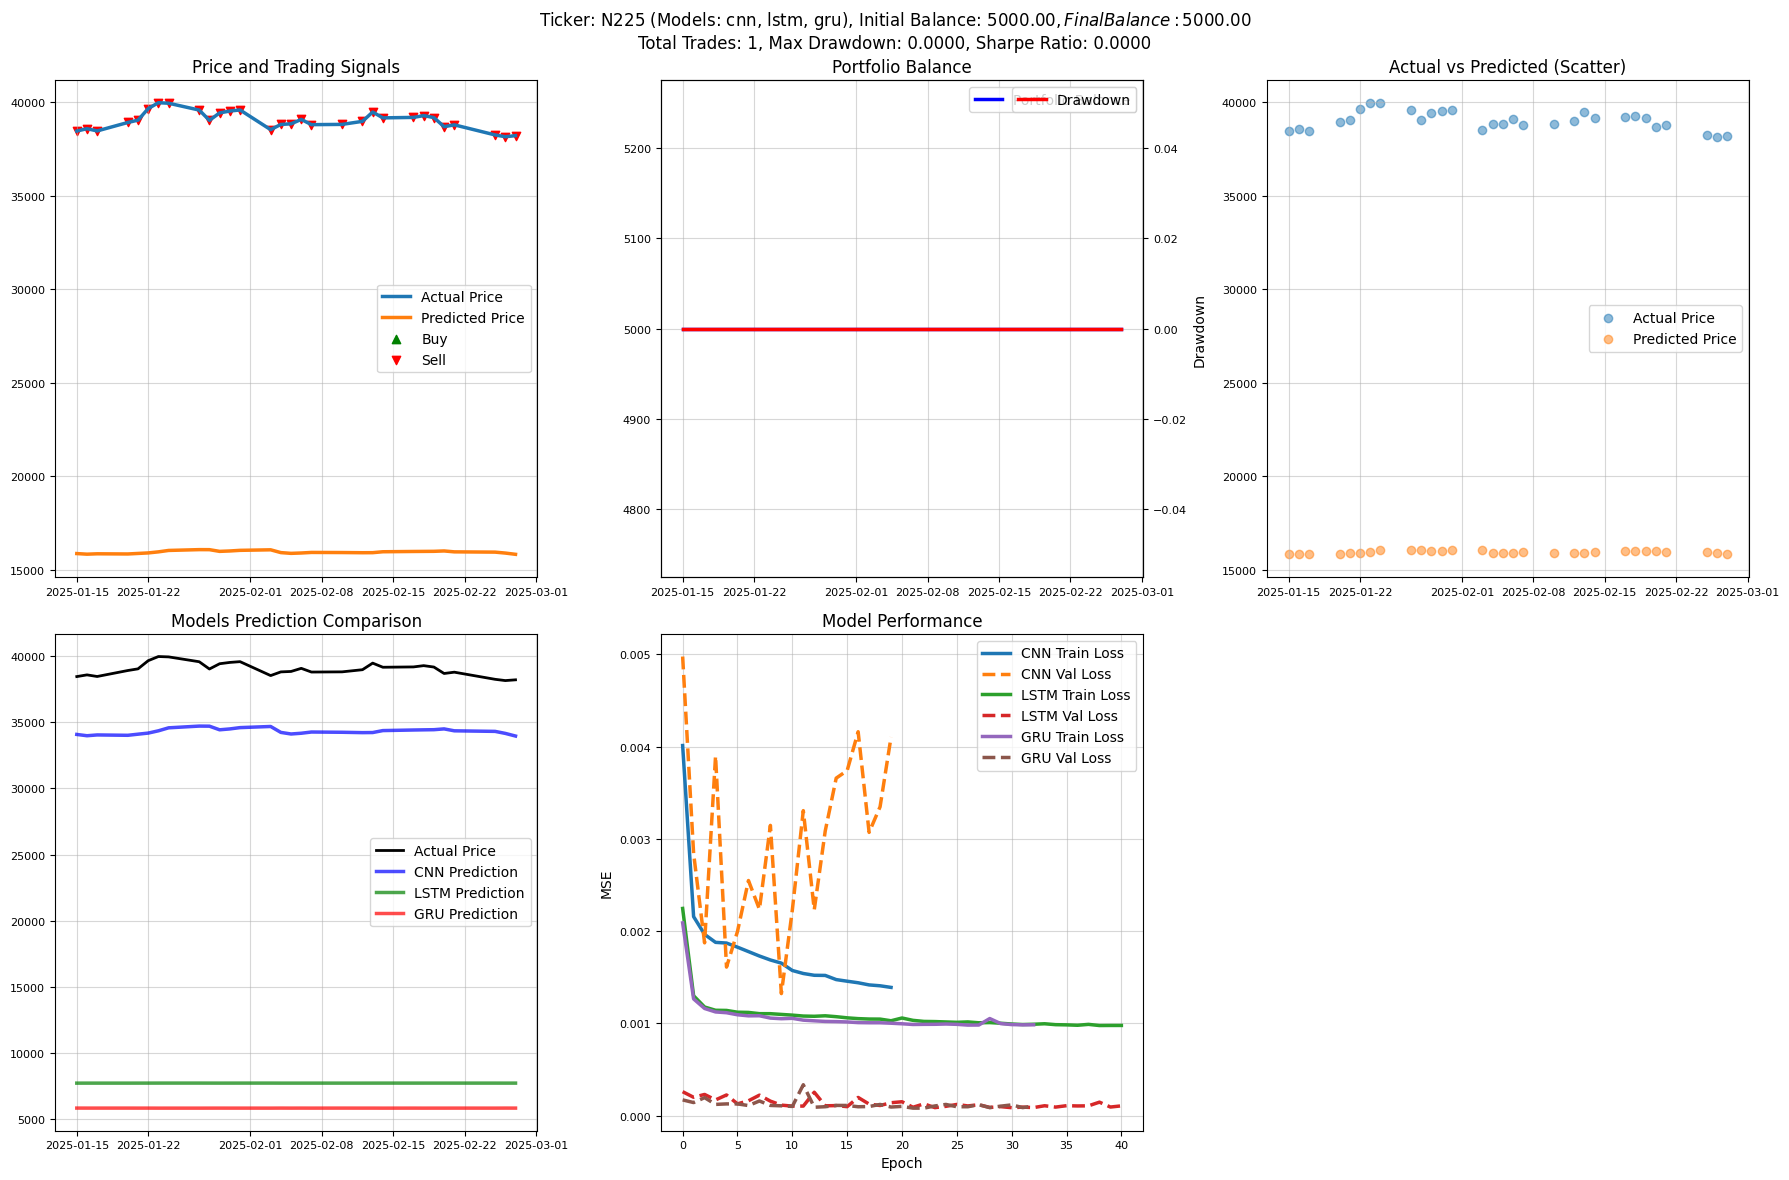


Ticker: HSI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: GSPC (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: DJI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: IXIC (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: GDAXI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: 0001.HK (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $3924.00
Total Trades: 1
Max Drawdown: 0.3699
Sharpe Ratio: -0.2075

Ticker: 1186.HK (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $6745.95
Total Trades: 1
Max Drawdown: 0.4079
Sharpe 

In [63]:
# Example usage
trader = StockTrader()
results = trader.run(data, model_types=['cnn', 'lstm', 'gru'], model_path='./models/stock_model',
                     load_model_flag=False, plot_days=30, additional_plot='scatter', ticker_to_plot='N225')

CNN model loaded from ./models/stock_model_cnn.keras
LSTM model loaded from ./models/stock_model_lstm.keras
GRU model loaded from ./models/stock_model_gru.keras

Ticker: N225 (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: HSI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: GSPC (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000


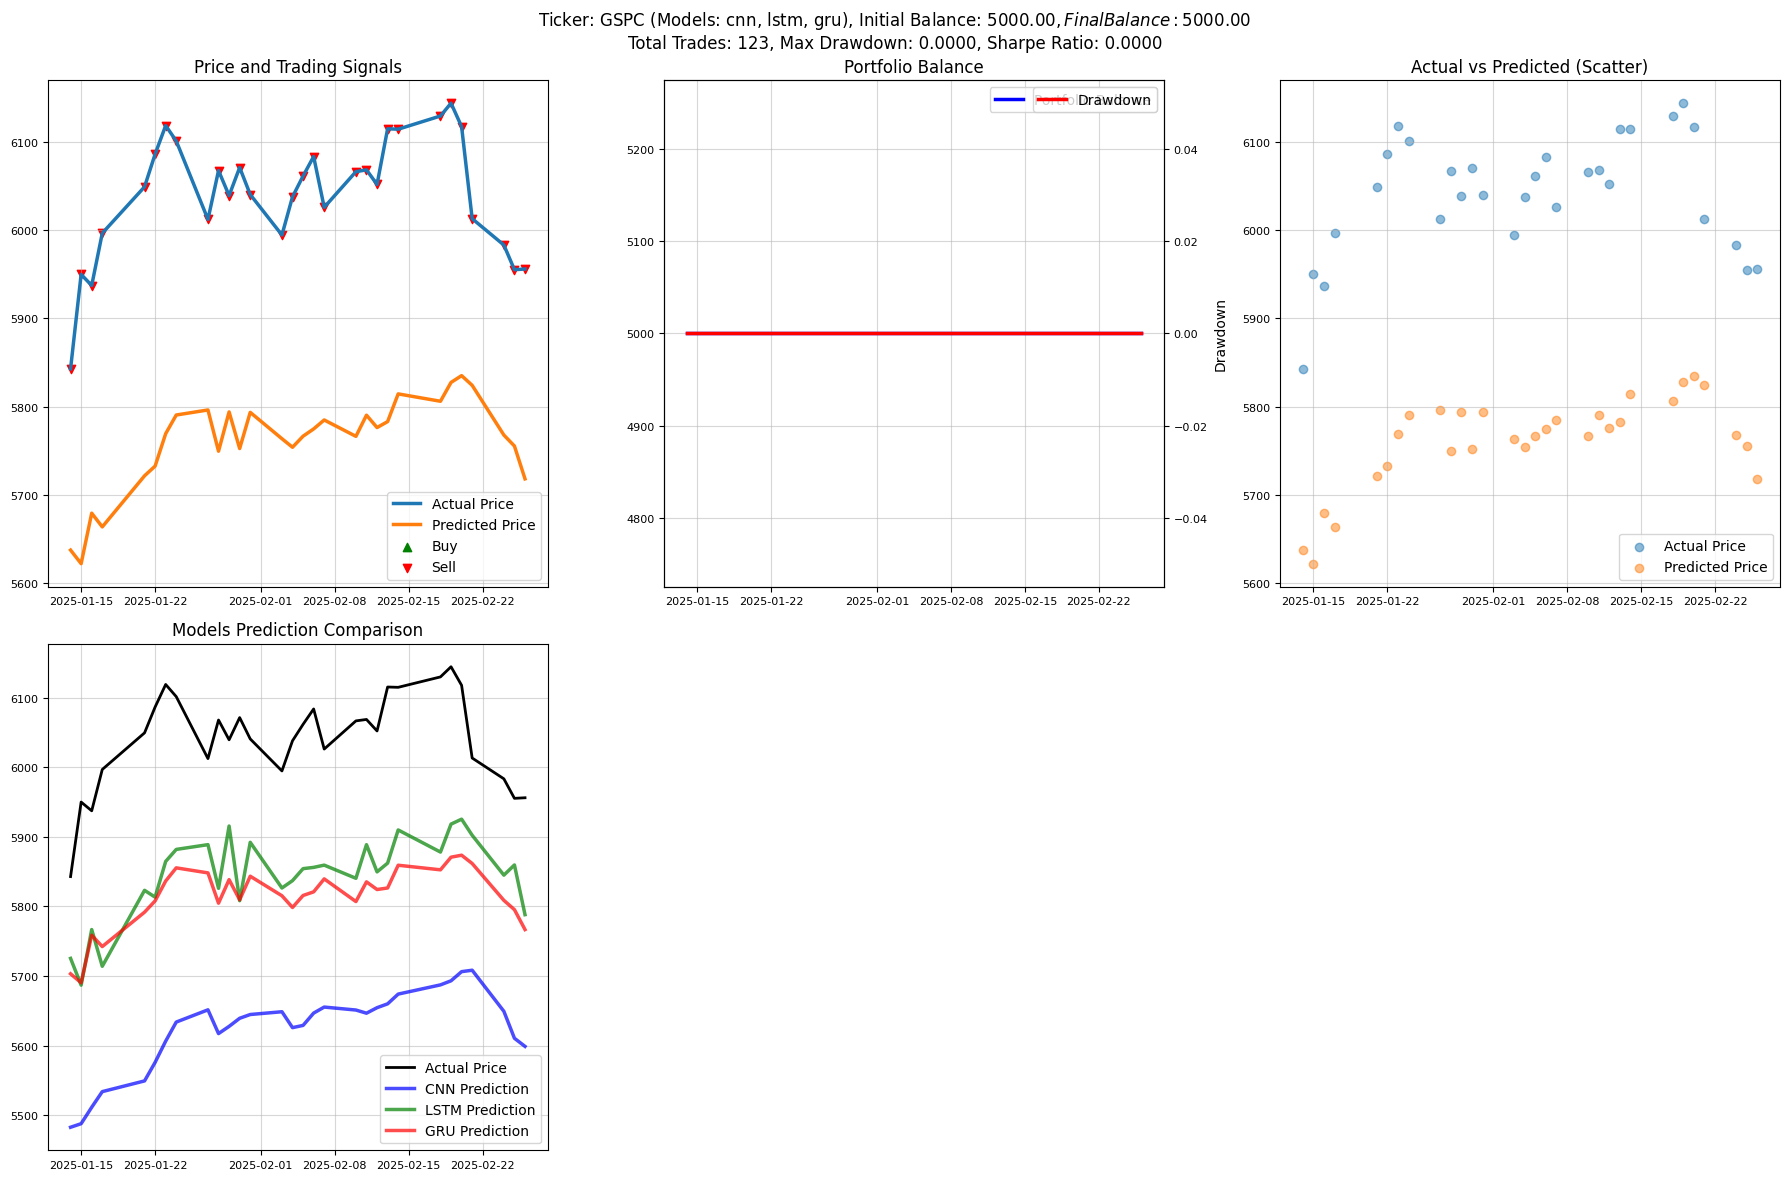


Ticker: DJI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: IXIC (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: GDAXI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: 0001.HK (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $3924.00
Total Trades: 1
Max Drawdown: 0.3699
Sharpe Ratio: -0.2075

Ticker: 1186.HK (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $6745.95
Total Trades: 1
Max Drawdown: 0.4079
Sharpe Ratio: 0.4020
Insufficient test data for ticker OEX

Ticker: FCHI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $5000.00
Total Trades: 0
Max Drawdown: 0.0000
Sharpe Ratio: 0.0000

Ticker: STI (Models: cnn, lstm, gru)
Initial Balance: $5000
Final Balance: $173.65
Total T

In [64]:
# Load and use only GRU
trader = StockTrader()
results = trader.run(data, model_types=['cnn', 'lstm', 'gru'], model_path='./models/stock_model', 
                     load_model_flag=True, plot_days=30, additional_plot='scatter', ticker_to_plot='GSPC')